# Sprint 1 — PLN: a linguagem da operação rodoviária
Challenge Motiva–FIAP · camada de NLU do agente de voz

Este notebook roda de ponta a ponta. Cada seção verifica se os dados da etapa anterior já existem; se ainda não existirem, ela avisa e segue.

| Seção | Depende de |
|---|---|
| 1. Taxonomia e cobertura | nada |
| 2. Normalização (testes) | nada |
| 3. Transcrição com Whisper | áudios no Drive |
| 4. Planilhas de anotação | seção 3 |
| 5. Kappa e gate | as duas planilhas preenchidas |
| 6. Corpus + validação | seção 5 |
| 7. Estatísticas, baseline e métricas | seção 6 |
| 8. Revisão de acurácia (Whisper large-v3, regras v2) | seção 6 e transcrição large-v3 |

In [1]:
# === Configuração ===
import os, sys, json, csv
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
# Raiz do projeto = a pasta que contém taxonomia_intencoes.json: a pasta atual (repositório clonado)
# ou, no Colab, a pasta no Drive em MyDrive/challenge-motiva/sprint1-pln (v0.2.3).
CANDIDATAS = [Path.cwd(), Path.cwd() / "sprint1-pln"]
if EM_COLAB and not any((c / "taxonomia_intencoes.json").exists() for c in CANDIDATAS):
    from google.colab import drive
    drive.mount("/content/drive")
    CANDIDATAS.append(Path("/content/drive/MyDrive/challenge-motiva/sprint1-pln"))
RAIZ = next((c for c in CANDIDATAS if (c / "taxonomia_intencoes.json").exists()), None)
assert RAIZ, "Pasta do projeto não encontrada: rode o notebook de dentro da pasta sprint1-pln ou com ela no Drive."
PASTA_AUDIOS = RAIZ.parent / "audios-sprint1"   # os áudios não vão para o repositório (voz é dado pessoal)
if EM_COLAB:
    !pip -q install jsonschema

sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))          # para importar tests/ (v0.1.7)
DADOS = RAIZ / "dados"
print("raiz:", RAIZ, "| colab:", EM_COLAB)

raiz: /content/teste_repro/sprint1-pln | colab: True


In [2]:
import pandas as pd
from normalizacao import Normalizador
from baseline import classificar, ExtratorEntidades
from kappa import gate
from corpus import ler_csv, gerar_planilhas_anotacao, montar_corpus, estatisticas, concordancia_entidades, parse_entidades
from validacao import validar, avisos_permissao, salvar_schema
from metricas import cobertura_taxonomia, acuracia_baseline, taxa_normalizacao

TAX = json.loads((RAIZ / "taxonomia_intencoes.json").read_text(encoding="utf-8"))
ENT = json.loads((DADOS / "esquema_entidades.json").read_text(encoding="utf-8"))
GLOSSARIO = RAIZ / "glossario_rodoviario.json"
N = Normalizador(GLOSSARIO)
EXT = ExtratorEntidades(GLOSSARIO)
salvar_schema(TAX, ENT, DADOS / "schema_corpus.json")
METRICAS = {}

## 1. Taxonomia de intenções e cobertura das 40 user stories

In [3]:
cob = cobertura_taxonomia(TAX)
METRICAS["cobertura_taxonomia"] = cob["cobertura"]
print(f"Cobertura: {cob['mapeadas']}/{cob['stories']} = {cob['cobertura']:.0%}")
pd.DataFrame([{"intencao": i["nome"], "tipo": i["tipo"], "criticidade": i["criticidade"],
               "confirma": i["exige_confirmacao"], "sensivel": i["dado_sensivel"],
               "personas": ", ".join(i["personas_autorizadas"]), "stories": ", ".join(i["user_stories"])}
              for i in TAX["intencoes"]])

Cobertura: 40/40 = 100%


,intencao,tipo,criticidade,confirma,sensivel,personas,stories
0,registrar_ocorrencia,dominio,alta,True,False,inspecao_trafego,P1-US1
1,relatar_condicoes,dominio,media,True,False,"inspecao_trafego, guincho","P1-US3, P2-US5"
2,registrar_dados_atendimento,dominio,alta,True,True,aph,P3-US2
3,consultar_procedimento,dominio,baixa,False,False,"inspecao_trafego, guincho, aph","P1-US2, P3-US1"
4,consultar_dados_ocorrencia,dominio,baixa,False,False,"inspecao_trafego, guincho, aph, supervisor, ge...","P2-US1, P2-US3, P3-US4"
5,consultar_recursos,dominio,baixa,False,False,"inspecao_trafego, aph, supervisor, gerente","P1-US4, P4-US3, P5-US6"
6,atualizar_status,dominio,media,True,False,"inspecao_trafego, guincho, aph","P1-US5, P2-US2, P2-US4, P2-US7, P3-US3, P3-US6"
7,solicitar_apoio,dominio,alta,True,False,"inspecao_trafego, guincho, aph","P1-US6, P2-US6, P3-US5"
8,encerrar_atendimento,dominio,alta,True,False,"inspecao_trafego, guincho","P1-US8, P2-US8"
9,gerar_resumo,dominio,media,True,False,"aph, supervisor, gerente","P3-US8, P4-US8, P5-US7"


## 2. Pipeline de normalização — testes

In [4]:
import importlib, tests.test_normalizacao as T  # noqa
importlib.reload(T)
T.test_casos(); T.test_span()
print(f"{len(T.CASOS)} casos de normalização passaram")
pd.DataFrame([{"entrada": e, "normalizado": N.normalizar(e)} for e, _ in T.CASOS[:8]])

17 casos de normalização passaram


,entrada,normalizado
0,registra aí uma ocorrencia no km cento e vinte...,registrar uma ocorrência no km 123.5 sentido c...
1,Informa que tem óleo na pista no km cinquenta ...,informar que tem óleo na pista no km 51.3 sent...
2,Guincho chegando no local da ocorrência três q...,guincho chegando no local da ocorrência 347 pr...
3,"Finaliza a missão, via liberada às quinze e qu...",finalizar a missão via liberada às 15:40
4,"Ó, tô no km oitenta e sete sentido interior, a...",tô no km 87 sentido interior acidente com 2 ca...
5,Hã... registra no quilômetro duzentos e quatro,registrar no km 204
6,"KM 123,5 sentido litoral",km 123.5 sentido litoral
7,km 51+300,km 51.3


## 3. Transcrição com Whisper small
Os áudios ficam no Drive (`enu_0001.m4a`, …). Só o texto vai para o repositório.

In [5]:
ARQ_BRUTAS = DADOS / "transcricoes_brutas.csv"
RODAR_TRANSCRICAO = EM_COLAB and not ARQ_BRUTAS.exists()   # mude para True para refazer

if RODAR_TRANSCRICAO:
    from transcricao import transcrever_pasta
    transcrever_pasta(PASTA_AUDIOS, ARQ_BRUTAS)

if ARQ_BRUTAS.exists():
    brutas = ler_csv(ARQ_BRUTAS)
    TRANSCRICOES = [{"id": b["id"], "transcricao_bruta": b["transcricao_bruta"],
                     "texto_normalizado": N.normalizar(b["transcricao_bruta"])} for b in brutas]
    with open(DADOS / "transcricoes_normalizadas.csv", "w", encoding="utf-8", newline="") as f:
        w = csv.DictWriter(f, fieldnames=["id", "transcricao_bruta", "texto_normalizado"]); w.writeheader(); w.writerows(TRANSCRICOES)
    print(len(TRANSCRICOES), "transcrições normalizadas")
    display(pd.DataFrame(TRANSCRICOES).head(10))
else:
    TRANSCRICOES = []
    print("Aguardando áudios: nenhuma transcrição ainda.")

29 transcrições normalizadas


,id,transcricao_bruta,texto_normalizado
0,enu_0001,Registro uma ocorrência no quilômetro de cento...,registro uma ocorrência no km 143.5 o sinche d...
1,enu_0002,"Registro uma ocorrência no quilômetro 225, ani...",registro uma ocorrência no km 225 animal morto...
2,enu_0003,Registro uma ocorrência no quilômetro 200. Sen...,registro uma ocorrência no km 200 sentido capi...
3,enu_0004,"Registram o acidente aqui na região central, f...",registram o acidente aqui na região central fa...
4,enu_0005,Eu estou aqui para no acostamento e tenho um a...,eu estou aqui para no acostamento e tenho um a...
5,enu_0006,"Carro do Acustamento, Km 227, Cinchido Capital.",carro do acustamento km 227 cinchido capital
6,enu_0007,Que é a fe? Tem um tombamento aqui no km 125 e...,que é a fe tem um tombamento aqui no km 125.5
7,enu_0008,"Tem um carro burado, pneu aqui, precisando de ...",tem um carro burado pneu aqui precisando de aj...
8,enu_0009,"Central, está de ambulância aqui no quilômetro...",central está de ambulância aqui no km 95 senti...
9,enu_0010,"D.A.P. manda um guicho pesado, teve uma corren...",d a p mandar um guicho pesado teve uma correnc...


## 4. Planilhas de anotação
Uma por anotador, sem a intenção do roteiro. Formato da coluna `entidades`: `tipo=valor@trecho; ...`

In [6]:
# Persona de cada áudio: dados/personas.csv (id, persona), extraído da planilha de controle das gravações (v0.2.3).
ARQ_PERSONAS = DADOS / "personas.csv"
PERSONAS = {r["id"]: r["persona"].strip() for r in ler_csv(ARQ_PERSONAS) if r["persona"].strip()}
_sem = sorted({t["id"] for t in TRANSCRICOES} - set(PERSONAS))
if _sem: print("Sem persona em dados/personas.csv:", _sem)
print(len(PERSONAS), "personas lidas de dados/personas.csv")
if TRANSCRICOES:
    gerar_planilhas_anotacao(TRANSCRICOES, DADOS)
else:
    print("Aguardando transcrições.")

29 personas lidas de dados/personas.csv
já existe, não sobrescrevi: /content/teste_repro/sprint1-pln/dados/anotacao_a1.csv
já existe, não sobrescrevi: /content/teste_repro/sprint1-pln/dados/anotacao_a2.csv


## 5. Concordância entre anotadores (Cohen's kappa) e gate

In [7]:
def anotacao_completa(caminho):
    return caminho.exists() and all(r["intencao"].strip() for r in ler_csv(caminho))

A1, A2 = DADOS / "anotacao_a1.csv", DADOS / "anotacao_a2.csv"
if anotacao_completa(A1) and anotacao_completa(A2):
    an1, an2 = ler_csv(A1), ler_csv(A2)
    ids = [r["id"] for r in an1]
    m2 = {r["id"]: r for r in an2}
    g = gate([r["intencao"].strip() for r in an1], [m2[i]["intencao"].strip() for i in ids])
    METRICAS["kappa_intencao"] = g["kappa_geral"]
    print(f"kappa geral = {g['kappa_geral']}  (limiar {g['limiar']}) -> {'PASSA' if g['passa_geral'] else 'NÃO PASSA'}")
    print("Intenções abaixo do limiar (redefinir ou fundir):", list(g["intencoes_abaixo_do_limiar"]) or "nenhuma")
    tmap = {t["id"]: t["texto_normalizado"] for t in TRANSCRICOES}
    f1 = [concordancia_entidades(parse_entidades(r["entidades"], tmap[r["id"]]), parse_entidades(m2[r["id"]]["entidades"], tmap[r["id"]])) for r in an1]
    METRICAS["concordancia_entidades_f1"] = round(sum(f1) / len(f1), 3)
    print("Concordância de entidades (F1 médio):", METRICAS["concordancia_entidades_f1"])
    display(pd.DataFrame(g["por_intencao"]).T.sort_values("kappa"))
    (DADOS / "relatorio_kappa.json").write_text(json.dumps(g, ensure_ascii=False, indent=2), encoding="utf-8")
else:
    an1 = an2 = None
    print("Aguardando as duas planilhas de anotação preenchidas.")

kappa geral = 0.717  (limiar 0.7) -> PASSA
Intenções abaixo do limiar (redefinir ou fundir): ['consultar_dados_ocorrencia', 'consultar_panorama', 'consultar_recursos', 'gerar_resumo', 'registrar_direcionamento', 'relatar_condicoes', 'solicitar_apoio']
Concordância de entidades (F1 médio): 0.784


,kappa,n_a1,n_a2
relatar_condicoes,0.000,0.0,2.0
registrar_direcionamento,0.000,1.0,0.0
solicitar_apoio,0.583,5.0,7.0
consultar_dados_ocorrencia,0.651,2.0,1.0
gerar_resumo,0.651,1.0,2.0
consultar_panorama,0.651,2.0,1.0
consultar_recursos,0.651,1.0,2.0
atualizar_status,0.782,3.0,2.0
registrar_ocorrencia,0.828,9.0,7.0
registrar_dados_atendimento,1.000,1.0,1.0


## 6. Corpus anotado + validação contra o contrato

In [8]:
ARQ_FINAL = DADOS / "anotacao_final.csv"   # adjudicação das discordâncias (opcional)
if an1 and an2:
    final = ler_csv(ARQ_FINAL) if ARQ_FINAL.exists() else None
    CORPUS, pendentes = montar_corpus(TRANSCRICOES, PERSONAS, an1, an2, final, TAX)
    erros = validar(CORPUS, TAX, ENT)
    print(len(CORPUS), "registros |", len(pendentes), "pendentes |", len(erros), "erros de schema")
    for p in pendentes[:20]: print("  pendente:", p)
    for e in erros[:20]: print("  ERRO:", e)
    print("Persona sem permissão para a intenção (governança):", avisos_permissao(CORPUS, TAX) or "nenhuma")
    if not erros:
        (RAIZ / "corpus_enunciacoes.json").write_text(json.dumps(CORPUS, ensure_ascii=False, indent=2), encoding="utf-8")
        print("corpus_enunciacoes.json salvo")
else:
    CORPUS = []
    print("Aguardando anotações.")

29 registros | 0 pendentes | 0 erros de schema
Persona sem permissão para a intenção (governança): ['enu_0016', 'enu_0028']
corpus_enunciacoes.json salvo


## 7. Estatísticas, baseline e métricas

{
  "n_enunciacoes": 29,
  "vocabulario_bruto": 211,
  "vocabulario_normalizado": 185,
  "comprimento_medio_tokens": 13.38,
  "distribuicao_intencao": {
    "registrar_ocorrencia": 9,
    "solicitar_apoio": 7,
    "consultar_indicadores": 3,
    "atualizar_status": 2,
    "consultar_dados_ocorrencia": 2,
    "consultar_panorama": 2,
    "consultar_recursos": 1,
    "gerar_resumo": 1,
    "registrar_dados_atendimento": 1,
    "encerrar_atendimento": 1
  },
  "distribuicao_persona": {
    "inspecao_trafego": 12,
    "aph": 6,
    "supervisor": 5,
    "gerente": 5,
    "guincho": 1
  }
}


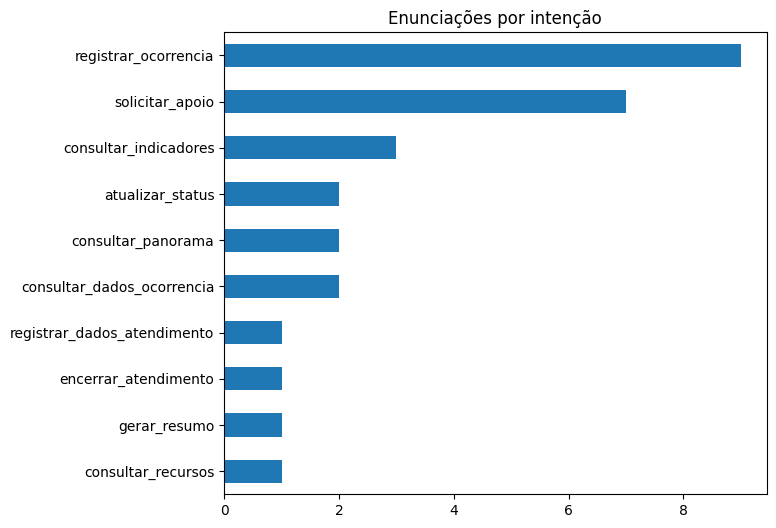

In [9]:
if CORPUS:
    est = estatisticas(CORPUS)
    print(json.dumps({k: v for k, v in est.items() if k != "palavras_mais_frequentes"}, ensure_ascii=False, indent=2))
    pd.Series(est["distribuicao_intencao"]).sort_values().plot.barh(figsize=(7, 6), title="Enunciações por intenção")
else:
    print("Aguardando corpus.")

In [10]:
if CORPUS:
    ab = acuracia_baseline(CORPUS)
    tn = taxa_normalizacao(CORPUS)
    METRICAS["acuracia_baseline"] = ab["acuracia"]
    METRICAS["taxa_normalizacao_numerica"] = tn["taxa"]
    print(f"Acurácia do baseline: {ab['acertos']}/{ab['total']} = {ab['acuracia']}")
    print("Confusões mais comuns (ouro, previsto):", ab["confusoes_mais_comuns"])
    print(f"Normalização numérica: {tn['convertidas']}/{tn['entidades_numericas']} = {tn['taxa']}")
    for f in tn["falhas"]: print("  não convertida:", f)

Acurácia do baseline: 12/29 = 0.414
Confusões mais comuns (ouro, previsto): [(('registrar_ocorrencia', 'fora_de_escopo'), 6), (('solicitar_apoio', 'fora_de_escopo'), 2), (('solicitar_apoio', 'atualizar_status'), 1), (('solicitar_apoio', 'registrar_ocorrencia'), 1), (('consultar_recursos', 'fora_de_escopo'), 1), (('consultar_dados_ocorrencia', 'fora_de_escopo'), 1), (('consultar_indicadores', 'consultar_panorama'), 1), (('gerar_resumo', 'fora_de_escopo'), 1), (('consultar_indicadores', 'registrar_ocorrencia'), 1), (('consultar_panorama', 'fora_de_escopo'), 1)]
Normalização numérica: 16/16 = 1.0


In [11]:
ex = N.normalizar("registra aí uma ocorrencia no km cento e vinte e tres e meio sentido capital")
print(ex); print(classificar(ex)); print(EXT.extrair(ex))

registrar uma ocorrência no km 123.5 sentido capital
('registrar_ocorrencia', {'registrar_ocorrencia': 4})
[{'tipo': 'km', 'valor': 123.5, 'span': [28, 36]}, {'tipo': 'sentido', 'valor': 'capital', 'span': [37, 52]}]


## 8. Revisão de acurácia: Whisper large-v3 e regras v2
Pedido do professor: aumentar a acurácia. Duas mudanças, medidas contra os **mesmos rótulos de intenção** do corpus:
1. transcrição com o Whisper large-v3 (`dados/transcricoes_brutas_large_v3.csv`), comparada com o small pelo WER;
2. regras v2 do baseline (`classificar_v2`). A v1 não muda.

**Atenção:** as regras v2 foram escritas depois da análise de erros deste corpus, então a acurácia delas aqui é otimista. A v1 é a medida sem viés. Ver DECISOES.md, "Revisão de acurácia (30/10/2026)".

In [12]:
import re
def _palavras(t): return re.sub(r"[^\w\s]", " ", (t or "").lower()).split()
def _erros(ref, hip):
    d = list(range(len(hip) + 1))
    for i, r in enumerate(ref, 1):
        ant, d[0] = d[0], i
        for j, h in enumerate(hip, 1):
            ant, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1, ant + (r != h))
    return d[-1]
wer = pd.read_csv(DADOS / "comparacao_wer_small_large.csv", dtype=str).fillna("")
_tot = sum(len(_palavras(o)) for o in wer["oficial"])
for col, nome in (("small", "wer_whisper_small"), ("large_v3", "wer_whisper_large_v3")):
    METRICAS[nome] = round(sum(_erros(_palavras(o), _palavras(h)) for o, h in zip(wer["oficial"], wer[col])) / _tot, 3)
print(f"WER Whisper small: {METRICAS['wer_whisper_small']:.1%} | Whisper large-v3: {METRICAS['wer_whisper_large_v3']:.1%}")

WER Whisper small: 35.0% | Whisper large-v3: 27.5%


In [13]:
import importlib, baseline
importlib.reload(baseline)
from baseline import classificar_v2
_lg = {r["id"]: r["transcricao_bruta"] for r in ler_csv(DADOS / "transcricoes_brutas_large_v3.csv")}
if CORPUS:
    comp = []
    for r in CORPUS:
        t_sm, t_lg = r["texto_normalizado"], N.normalizar(_lg[r["id"]])
        comp.append({"id": r["id"], "ouro": r["intencao"],
                     "v1_small": classificar(t_sm)[0], "v1_large_v3": classificar(t_lg)[0],
                     "v2_small": classificar_v2(t_sm)[0], "v2_large_v3": classificar_v2(t_lg)[0]})
    comp = pd.DataFrame(comp); n = len(comp); tabela = []
    for versao in ("v1", "v2"):
        lin = {"regras": versao}
        for asr in ("small", "large_v3"):
            acertos = int((comp[f"{versao}_{asr}"] == comp["ouro"]).sum())
            lin[f"Whisper {asr}"] = f"{acertos}/{n} = {acertos / n:.1%}"
            METRICAS[f"acuracia_regras_{versao}_{asr}"] = round(acertos / n, 3)
        tabela.append(lin)
    display(pd.DataFrame(tabela))
    print("Frases que a v2 ainda erra:")
    display(comp[(comp["v2_small"] != comp["ouro"]) | (comp["v2_large_v3"] != comp["ouro"])])
else:
    print("Aguardando corpus.")

,regras,Whisper small,Whisper large_v3
0,v1,12/29 = 41.4%,15/29 = 51.7%
1,v2,26/29 = 89.7%,29/29 = 100.0%


Frases que a v2 ainda erra:


,id,ouro,v1_small,v1_large_v3,v2_small,v2_large_v3
5,enu_0006,registrar_ocorrencia,fora_de_escopo,fora_de_escopo,fora_de_escopo,registrar_ocorrencia
7,enu_0008,registrar_ocorrencia,fora_de_escopo,fora_de_escopo,fora_de_escopo,registrar_ocorrencia
13,enu_0014,solicitar_apoio,registrar_ocorrencia,solicitar_apoio,registrar_ocorrencia,solicitar_apoio


## Resumo das métricas de referência

In [14]:
ref = {"cobertura_taxonomia": "100%", "kappa_intencao": "≥ 0,70", "acuracia_baseline": "reportada",
       "taxa_normalizacao_numerica": "≥ 90%", "concordancia_entidades_f1": "(extra)",
       "wer_whisper_small": "reportado (seção 8)", "wer_whisper_large_v3": "reportado (seção 8)",
       "acuracia_regras_v1_large_v3": "reportada (seção 8)",
       "acuracia_regras_v2_small": "≥ 80% (meta do professor); otimista, seção 8", "acuracia_regras_v2_large_v3": "≥ 80% (meta do professor); otimista, seção 8"}
pd.DataFrame([{"métrica": k, "valor": METRICAS.get(k, "aguardando dados"), "patamar": v} for k, v in ref.items()])

,métrica,valor,patamar
0,cobertura_taxonomia,1.000,100%
1,kappa_intencao,0.717,"≥ 0,70"
2,acuracia_baseline,0.414,reportada
3,taxa_normalizacao_numerica,1.000,≥ 90%
4,concordancia_entidades_f1,0.784,(extra)
5,wer_whisper_small,0.350,reportado (seção 8)
6,wer_whisper_large_v3,0.275,reportado (seção 8)
7,acuracia_regras_v1_large_v3,0.517,reportada (seção 8)
8,acuracia_regras_v2_small,0.897,"≥ 80% (meta do professor); otimista, seção 8"
9,acuracia_regras_v2_large_v3,1.000,"≥ 80% (meta do professor); otimista, seção 8"
